In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_path = "../data/raw/Telco-Customer-Churn.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())



Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values per column:")
print(df.isnull().sum())


Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecur

In [6]:

# 1. Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# 2. Check duplicate customer IDs
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

# 3. Check blank or whitespace-only values
blank_counts = df.select_dtypes(include="object").apply(
    lambda col: col.str.strip().eq("").sum()
)

print("\nBlank strings in text columns:")
print(blank_counts[blank_counts > 0])

# 4. Check whether TotalCharges can be converted to numbers
total_charges_numeric = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

print("\nTotalCharges values that cannot be converted:",
      total_charges_numeric.isna().sum())

print("\nRows with invalid TotalCharges:")
display(df.loc[total_charges_numeric.isna(),
               ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]])


Duplicate rows: 0
Duplicate customer IDs: 0

Blank strings in text columns:
TotalCharges    11
dtype: int64

TotalCharges values that cannot be converted: 11

Rows with invalid TotalCharges:


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


In [7]:

# Create a working copy so the raw DataFrame remains unchanged
df_clean = df.copy()

# Convert blank strings to missing values, then convert to numeric
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"].astype(str).str.strip().replace("", np.nan),
    errors="coerce"
)

# Verify the change
print("TotalCharges data type:",
      df_clean["TotalCharges"].dtype)

print("Missing TotalCharges values:",
      df_clean["TotalCharges"].isna().sum())

print("\nAffected records:")
display(
    df_clean.loc[
        df_clean["TotalCharges"].isna(),
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
    ]
)

print("\nUpdated data types:")
df_clean.info()


TotalCharges data type: float64
Missing TotalCharges values: 11

Affected records:


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN



Updated data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

In [8]:

print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))

print("\nDuplicate customer IDs:",
      df_clean["customerID"].duplicated().sum())

print("\nMissing values after cleaning:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

print("\nTenure of records with missing TotalCharges:")
print(
    df_clean.loc[df_clean["TotalCharges"].isna(), "tenure"]
    .value_counts()
)


Original rows: 7043
Cleaned rows: 7043

Duplicate customer IDs: 0

Missing values after cleaning:
TotalCharges    11
dtype: int64

Tenure of records with missing TotalCharges:
tenure
0    11
Name: count, dtype: int64


In [9]:

categorical_columns = df_clean.select_dtypes(
    include="object"
).columns.drop("customerID")

for col in categorical_columns:
    print(f"\n--- {col} ---")
    print(df_clean[col].value_counts(dropna=False))



--- gender ---
gender
Male      3555
Female    3488
Name: count, dtype: int64

--- Partner ---
Partner
No     3641
Yes    3402
Name: count, dtype: int64

--- Dependents ---
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

--- PhoneService ---
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

--- MultipleLines ---
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

--- InternetService ---
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

--- OnlineSecurity ---
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

--- OnlineBackup ---
OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64

--- DeviceProtection ---
DeviceProtection
No                     3095
Yes                    2422
No internet service   

In [10]:

numeric_columns = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

print(df_clean[numeric_columns].describe().T)

print("\nSeniorCitizen values:")
print(df_clean["SeniorCitizen"].value_counts(dropna=False))

print("\nNegative tenure values:",
      (df_clean["tenure"] < 0).sum())

print("Negative monthly charges:",
      (df_clean["MonthlyCharges"] < 0).sum())

print("Negative total charges:",
      (df_clean["TotalCharges"] < 0).sum())


                 count         mean          std    min     25%       50%  \
SeniorCitizen   7043.0     0.162147     0.368612   0.00    0.00     0.000   
tenure          7043.0    32.371149    24.559481   0.00    9.00    29.000   
MonthlyCharges  7043.0    64.761692    30.090047  18.25   35.50    70.350   
TotalCharges    7032.0  2283.300441  2266.771362  18.80  401.45  1397.475   

                      75%      max  
SeniorCitizen      0.0000     1.00  
tenure            55.0000    72.00  
MonthlyCharges    89.8500   118.75  
TotalCharges    3794.7375  8684.80  

SeniorCitizen values:
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

Negative tenure values: 0
Negative monthly charges: 0
Negative total charges: 0


In [11]:

# Total unique customers
total_customers = df_clean["customerID"].nunique()

# Customers who churned
churned_customers = (
    df_clean["Churn"].eq("Yes").sum()
)

# Customers who stayed
retained_customers = (
    df_clean["Churn"].eq("No").sum()
)

# Calculate rates
churn_rate = churned_customers / total_customers * 100
retention_rate = retained_customers / total_customers * 100

# Display KPIs
print("CUSTOMER CHURN KPI SUMMARY")
print("-" * 35)
print(f"Total customers: {total_customers:,}")
print(f"Churned customers: {churned_customers:,}")
print(f"Retained customers: {retained_customers:,}")
print(f"Churn rate: {churn_rate:.2f}%")
print(f"Retention rate: {retention_rate:.2f}%")

# Validate the customer counts
print("\nValidation:")
print("Churned + retained = total:",
      churned_customers + retained_customers == total_customers)
print("Churn rate + retention rate:",
      f"{churn_rate + retention_rate:.2f}%")


CUSTOMER CHURN KPI SUMMARY
-----------------------------------
Total customers: 7,043
Churned customers: 1,869
Retained customers: 5,174
Churn rate: 26.54%
Retention rate: 73.46%

Validation:
Churned + retained = total: True
Churn rate + retention rate: 100.00%


In [12]:

contract_analysis = (
    df_clean.groupby("Contract")
    .agg(
        Total_Customers=("customerID", "nunique"),
        Churned_Customers=(
            "Churn",
            lambda x: (x == "Yes").sum()
        )
    )
    .reset_index()
)

contract_analysis["Churn_Rate_%"] = (
    contract_analysis["Churned_Customers"]
    / contract_analysis["Total_Customers"] * 100
)

contract_analysis = contract_analysis.sort_values(
    "Churn_Rate_%", ascending=False
)

display(contract_analysis.round(2))


,Contract,Total_Customers,Churned_Customers,Churn_Rate_%
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83


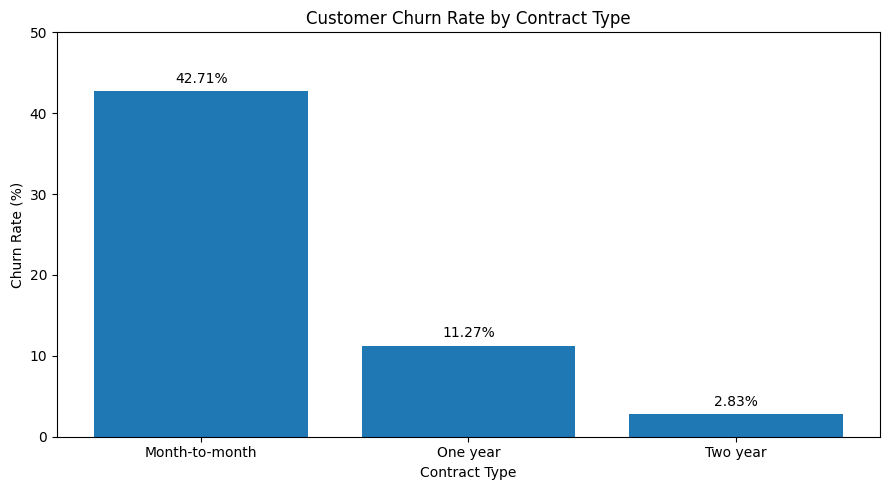

In [13]:

plt.figure(figsize=(9, 5))

plt.bar(
    contract_analysis["Contract"],
    contract_analysis["Churn_Rate_%"]
)

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)

for i, rate in enumerate(contract_analysis["Churn_Rate_%"]):
    plt.text(i, rate + 1, f"{rate:.2f}%", ha="center")

plt.tight_layout()
plt.show()


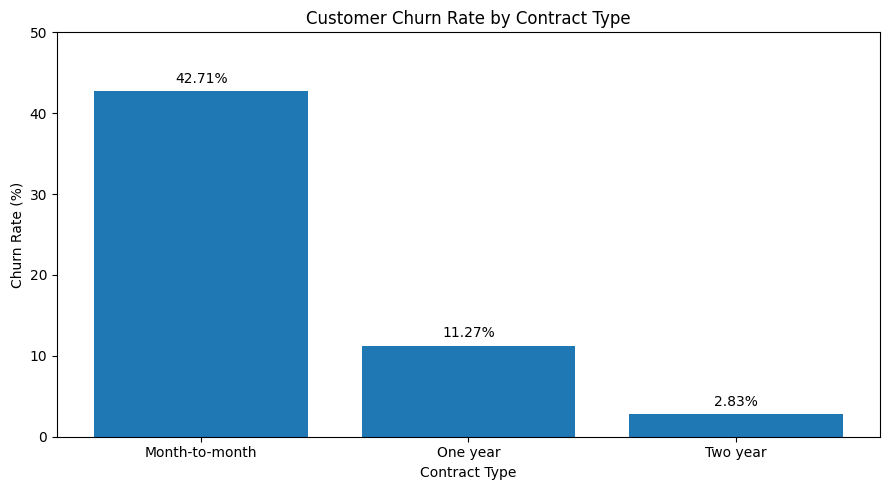

In [14]:

import os

os.makedirs("../visuals", exist_ok=True)

plt.figure(figsize=(9, 5))
plt.bar(
    contract_analysis["Contract"],
    contract_analysis["Churn_Rate_%"]
)

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)

for i, rate in enumerate(contract_analysis["Churn_Rate_%"]):
    plt.text(i, rate + 1, f"{rate:.2f}%", ha="center")

plt.tight_layout()
plt.savefig(
    "../visuals/churn_by_contract.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [15]:

# Create customer tenure groups
df_clean["TenureGroup"] = pd.cut(
    df_clean["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0–12 months", "13–24 months", "25–48 months", "49–72 months"]
)

# Calculate churn rate for each group
tenure_analysis = (
    df_clean.groupby("TenureGroup", observed=False)
    .agg(
        Total_Customers=("customerID", "nunique"),
        Churned_Customers=("Churn", lambda x: (x == "Yes").sum())
    )
    .reset_index()
)

tenure_analysis["Churn_Rate_%"] = (
    tenure_analysis["Churned_Customers"]
    / tenure_analysis["Total_Customers"] * 100
)

display(tenure_analysis.round(2))


,TenureGroup,Total_Customers,Churned_Customers,Churn_Rate_%
0,0–12 months,2186,1037,47.44
1,13–24 months,1024,294,28.71
2,25–48 months,1594,325,20.39
3,49–72 months,2239,213,9.51


In [16]:

churn_comparison = (
    df_clean.groupby("Churn")
    .agg(
        Customers=("customerID", "nunique"),
        Avg_Monthly_Charges=("MonthlyCharges", "mean"),
        Avg_Tenure_Months=("tenure", "mean")
    )
    .reset_index()
)

display(churn_comparison.round(2))


,Churn,Customers,Avg_Monthly_Charges,Avg_Tenure_Months
0,No,5174,61.27,37.57
1,Yes,1869,74.44,17.98


In [17]:

def analyze_churn_by(column):
    result = (
        df_clean.groupby(column, dropna=False)
        .agg(
            Total_Customers=("customerID", "nunique"),
            Churned_Customers=("Churn", lambda x: (x == "Yes").sum())
        )
        .reset_index()
    )

    result["Churn_Rate_%"] = (
        result["Churned_Customers"]
        / result["Total_Customers"] * 100
    )

    return result.sort_values("Churn_Rate_%", ascending=False).round(2)


print("Churn by Payment Method")
display(analyze_churn_by("PaymentMethod"))

print("Churn by Internet Service")
display(analyze_churn_by("InternetService"))


Churn by Payment Method


,PaymentMethod,Total_Customers,Churned_Customers,Churn_Rate_%
2,Electronic check,2365,1071,45.29
3,Mailed check,1612,308,19.11
0,Bank transfer (automatic),1544,258,16.71
1,Credit card (automatic),1522,232,15.24


Churn by Internet Service


,InternetService,Total_Customers,Churned_Customers,Churn_Rate_%
1,Fiber optic,3096,1297,41.89
0,DSL,2421,459,18.96
2,No,1526,113,7.40


In [18]:

import os

os.makedirs("../data/processed", exist_ok=True)

df_clean.to_csv(
    "../data/processed/customer_churn_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")
print("Dataset shape:", df_clean.shape)
print("Saved to: data/processed/customer_churn_cleaned.csv")


Cleaned dataset saved successfully!
Dataset shape: (7043, 22)
Saved to: data/processed/customer_churn_cleaned.csv
